# Trick or Data: The Science of Halloween Candy

## Objective

This project explores the relationship between candy attributes and
consumer preferences using the FiveThirtyEight Halloween Candy Power
Ranking dataset.

The goal is to identify which characteristics are associated with
higher candy popularity through exploratory data analysis and
statistical methods.

## Dataset

- **Source:** FiveThirtyEight
- **Records:** 85 candy products
- **Features:** 13 columns
- **Format:** CSV
- **Unit of observation:** One candy product

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
url = "https://raw.githubusercontent.com/fivethirtyeight/data/master/candy-power-ranking/candy-data.csv"

df = pd.read_csv(url)

In [4]:
df.head()

,competitorname,chocolate,fruity,caramel,peanutyalmondy,nougat,crispedricewafer,hard,bar,pluribus,sugarpercent,pricepercent,winpercent
0,100 Grand,1,0,1,0,0,1,0,1,0,0.732,0.860,66.971725
1,3 Musketeers,1,0,0,0,1,0,0,1,0,0.604,0.511,67.602936
2,One dime,0,0,0,0,0,0,0,0,0,0.011,0.116,32.261086
3,One quarter,0,0,0,0,0,0,0,0,0,0.011,0.511,46.116505
4,Air Heads,0,1,0,0,0,0,0,0,0,0.906,0.511,52.341465


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 85 entries, 0 to 84
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   competitorname    85 non-null     object 
 1   chocolate         85 non-null     int64  
 2   fruity            85 non-null     int64  
 3   caramel           85 non-null     int64  
 4   peanutyalmondy    85 non-null     int64  
 5   nougat            85 non-null     int64  
 6   crispedricewafer  85 non-null     int64  
 7   hard              85 non-null     int64  
 8   bar               85 non-null     int64  
 9   pluribus          85 non-null     int64  
 10  sugarpercent      85 non-null     float64
 11  pricepercent      85 non-null     float64
 12  winpercent        85 non-null     float64
dtypes: float64(3), int64(9), object(1)
memory usage: 8.8+ KB


In [6]:
df.describe()

,chocolate,fruity,caramel,peanutyalmondy,nougat,crispedricewafer,hard,bar,pluribus,sugarpercent,pricepercent,winpercent
count,85.000000,85.000000,85.000000,85.000000,85.000000,85.000000,85.000000,85.000000,85.000000,85.000000,85.000000,85.000000
mean,0.435294,0.447059,0.164706,0.164706,0.082353,0.082353,0.176471,0.247059,0.517647,0.478647,0.468882,50.316764
std,0.498738,0.500140,0.373116,0.373116,0.276533,0.276533,0.383482,0.433861,0.502654,0.282778,0.285740,14.714357
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.011000,0.011000,22.445341
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.220000,0.255000,39.141056
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.465000,0.465000,47.829754
75%,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.732000,0.651000,59.863998
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.988000,0.976000,84.180290


In [7]:
df['competitorname'].unique()

array(['100 Grand', '3 Musketeers', 'One dime', 'One quarter',
       'Air Heads', 'Almond Joy', 'Baby Ruth', 'Boston Baked Beans',
       'Candy Corn', 'Caramel Apple Pops', 'Charleston Chew',
       'Chewey Lemonhead Fruit Mix', 'Chiclets', 'Dots', 'Dum Dums',
       'Fruit Chews', 'Fun Dip', 'Gobstopper', 'Haribo Gold Bears',
       'Haribo Happy Cola', 'Haribo Sour Bears', 'Haribo Twin Snakes',
       "Hershey's Kisses", "Hershey's Krackel",
       "Hershey's Milk Chocolate", "Hershey's Special Dark", 'Jawbusters',
       'Junior Mints', 'Kit Kat', 'Laffy Taffy', 'Lemonhead',
       'Lifesavers big ring gummies', "Peanut butter M&M's", "M&M's",
       'Mike & Ike', 'Milk Duds', 'Milky Way', 'Milky Way Midnight',
       'Milky Way Simply Caramel', 'Mounds', 'Mr Good Bar', 'Nerds',
       'Nestle Butterfinger', 'Nestle Crunch', 'Nik L Nip', 'Now & Later',
       'Payday', 'Peanut M&Ms', 'Pixie Sticks', 'Pop Rocks', 'Red vines',
       "Reese's Miniatures", "Reese's Peanut Butter cup"

In [8]:
df['chocolate'].value_counts()

,count
chocolate,
0,48
1,37


In [9]:
df['winpercent'].describe()

,winpercent
count,85.000000
mean,50.316764
std,14.714357
min,22.445341
25%,39.141056
50%,47.829754
75%,59.863998
max,84.180290


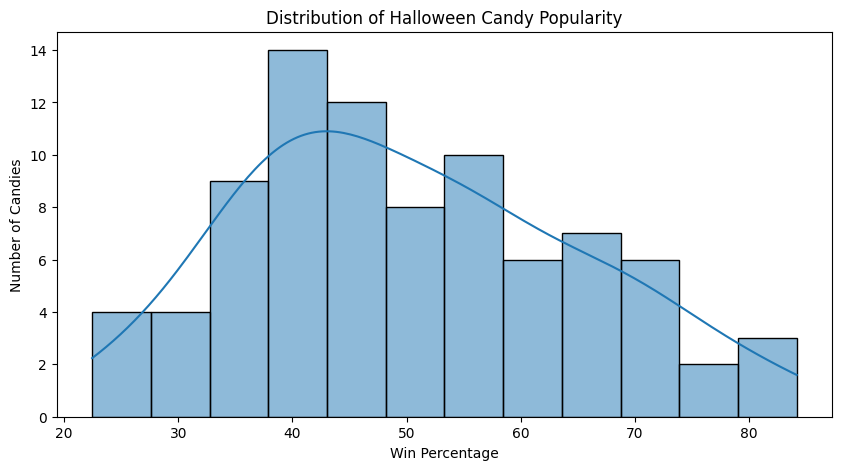

In [10]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='winpercent',
    bins=12,
    kde=True
)

plt.title('Distribution of Halloween Candy Popularity')
plt.xlabel('Win Percentage')
plt.ylabel('Number of Candies')

plt.show()

In [11]:
df.groupby('chocolate')

In [12]:
df.groupby('chocolate')['winpercent'].mean()

,winpercent
chocolate,
0,42.142257
1,60.921529


In the Halloween Candy Power Ranking dataset, chocolate-containing candies exhibited a higher average win percentage (60.92%) than non-chocolate candies (42.14%), representing a difference of approximately 18.78 percentage points.

In [13]:
df['chocolate'].value_counts()

,count
chocolate,
0,48
1,37


In [14]:
df.groupby('fruity')['winpercent'].mean()

,winpercent
fruity,
0,55.327122
1,44.119741


In [15]:
df['fruity'].value_counts()

,count
fruity,
0,47
1,38


In the Halloween Candy Power Ranking dataset, non-fruity candies exhibited a higher average win percentage (55.33%) than fruity candies (44.12%), representing a difference of approximately 11.21 percentage points.


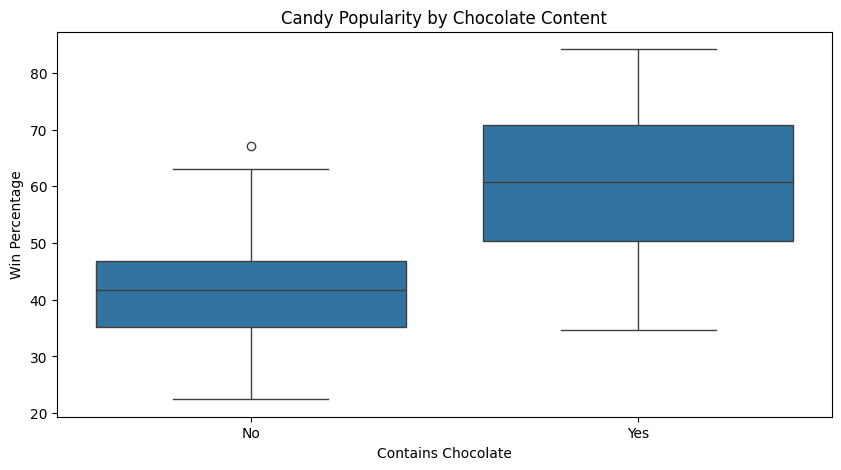

In [16]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x='chocolate',
    y='winpercent'
)

plt.title('Candy Popularity by Chocolate Content')
plt.xlabel('Contains Chocolate')
plt.ylabel('Win Percentage')

plt.xticks([0, 1], ['No', 'Yes'])

plt.show()

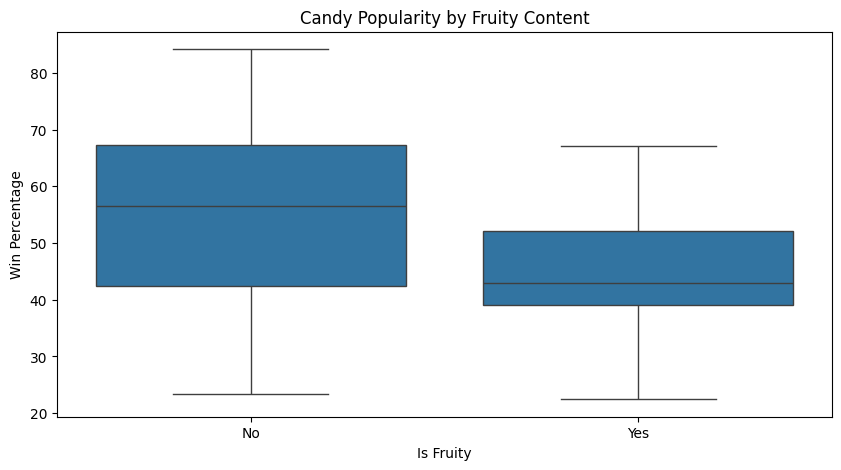

In [17]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x='fruity',
    y='winpercent'
)

plt.title('Candy Popularity by Fruity Content')
plt.xlabel('Is Fruity')
plt.ylabel('Win Percentage')

plt.xticks([0, 1], ['No', 'Yes'])

plt.show()

In [18]:
df.groupby('fruity')['winpercent'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
)

,count,mean,median,std,min,max
fruity,,,,,,
0,47,55.327122,56.490501,15.914216,23.417824,84.180290
1,38,44.119741,42.969034,10.263790,22.445341,67.037628


In [19]:
df.groupby('fruity')['winpercent'].quantile(
    [0.25, 0.50, 0.75]
)

fruity      
0       0.25    42.486603
        0.50    56.490501
        0.75    67.287330
1       0.25    39.044187
        0.50    42.969034
        0.75    52.109206
Name: winpercent, dtype: float64

Non-fruity candies exhibited greater variability in popularity than fruity candies. Their interquartile range was approximately 24.80 percentage points, compared to 13.07 percentage points for fruity candies.

In [20]:
df[['sugarpercent', 'winpercent']].corr()

,sugarpercent,winpercent
sugarpercent,1.000000,0.229151
winpercent,0.229151,1.000000


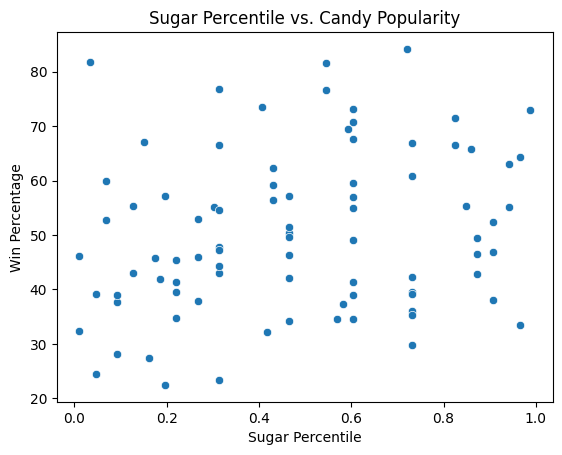

In [21]:
sns.scatterplot(data=df, x='sugarpercent', y='winpercent')

plt.title('Sugar Percentile vs. Candy Popularity')
plt.xlabel('Sugar Percentile')
plt.ylabel('Win Percentage')

plt.show()

In [22]:
df.groupby('chocolate')['sugarpercent'].mean()

,sugarpercent
chocolate,
0,0.452937
1,0.512000


In [23]:
df.groupby('chocolate').apply(
    lambda group: group['sugarpercent'].corr(group['winpercent'])
)

/tmp/ipykernel_1337/2255925252.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df.groupby('chocolate').apply(


,0
chocolate,
0,0.158820
1,0.297997


In [24]:
df.groupby('chocolate')[['sugarpercent', 'winpercent']].corr()

sugarpercent  winpercent
chocolate                                       
0         sugarpercent      1.000000    0.158820
          winpercent        0.158820    1.000000
1         sugarpercent      1.000000    0.297997
          winpercent        0.297997    1.000000

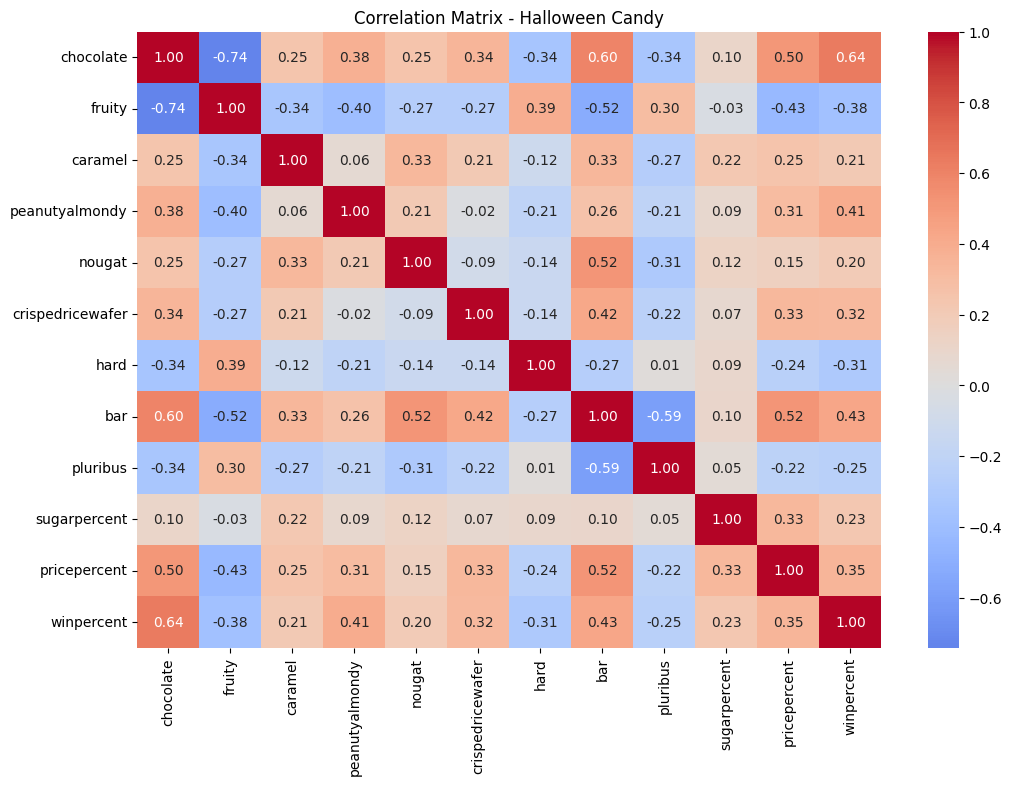

In [25]:
correlation_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    center=0
)

plt.title('Correlation Matrix - Halloween Candy')
plt.show()

In [26]:
correlation_matrix['winpercent'] \
    .drop('winpercent') \
    .sort_values(ascending=False)

,winpercent
chocolate,0.636517
bar,0.429929
peanutyalmondy,0.406192
pricepercent,0.345325
crispedricewafer,0.324680
sugarpercent,0.229151
caramel,0.213416
nougat,0.199375
pluribus,-0.247448
hard,-0.310382


In [27]:
df.groupby(['chocolate', 'bar'])['winpercent'].agg(
    ['count', 'mean', 'median']
)

count       mean     median
chocolate bar                             
0         0       47  42.053867  41.389557
          1        1  46.296597  46.296597
1         0       17  59.599384  57.219250
          1       20  62.045353  61.542591

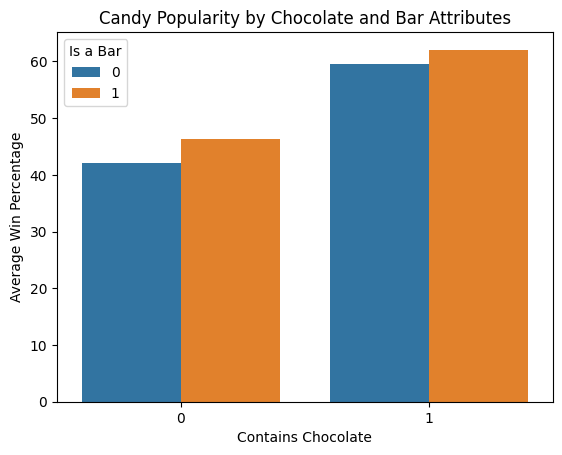

In [28]:
sns.barplot(
    data=df,
    x='chocolate',
    y='winpercent',
    hue='bar',
    errorbar=None
)

plt.title('Candy Popularity by Chocolate and Bar Attributes')
plt.xlabel('Contains Chocolate')
plt.ylabel('Average Win Percentage')
plt.legend(title='Is a Bar')
plt.show()

Chocolate was the characteristic most strongly associated with candy popularity. Although bar-shaped candies also showed a positive association with popularity, this relationship may be partially explained by the strong overlap between chocolate and bar attributes in the dataset.

In [29]:
df.duplicated().sum()

np.int64(0)

In [30]:
df.isnull().sum()

,0
competitorname,0
chocolate,0
fruity,0
caramel,0
peanutyalmondy,0
nougat,0
crispedricewafer,0
hard,0
bar,0
pluribus,0


In [31]:
binary_columns = [
    'chocolate',
    'fruity',
    'caramel',
    'peanutyalmondy',
    'nougat',
    'crispedricewafer',
    'hard',
    'bar',
    'pluribus'
]

In [32]:
for column in binary_columns:
    print(column, df[column].unique())

chocolate [1 0]
fruity [0 1]
caramel [1 0]
peanutyalmondy [0 1]
nougat [0 1]
crispedricewafer [1 0]
hard [0 1]
bar [1 0]
pluribus [0 1]


## Data Validation

The dataset was checked for duplicate records, missing values, and
invalid values in binary attributes.

- Duplicate records: 0
- Missing values: 0
- Binary attributes: all contain only 0 and 1

The dataset passed all three validation checks.

In [33]:
df.sort_values(
    by='winpercent',
    ascending=False
)[['competitorname', 'winpercent']].head(10)

,competitorname,winpercent
52,Reese's Peanut Butter cup,84.180290
51,Reese's Miniatures,81.866257
79,Twix,81.642914
28,Kit Kat,76.768600
64,Snickers,76.673782
53,Reese's pieces,73.434990
36,Milky Way,73.099556
54,Reese's stuffed with pieces,72.887901
32,Peanut butter M&M's,71.465050
42,Nestle Butterfinger,70.735641


In [34]:
df.sort_values(
    by='winpercent',
    ascending=True
)[['competitorname', 'winpercent']].head(10)

,competitorname,winpercent
44,Nik L Nip,22.445341
7,Boston Baked Beans,23.417824
12,Chiclets,24.524988
72,Super Bubble,27.303865
26,Jawbusters,28.127439
57,Root Beer Barrels,29.703691
71,Sugar Daddy,32.230995
2,One dime,32.261086
70,Sugar Babies,33.437550
19,Haribo Happy Cola,34.158958


In [35]:
top10 = df.nlargest(10, 'winpercent')
bottom10 = df.nsmallest(10, 'winpercent')

In [36]:
top10[binary_columns].mean()

,0
chocolate,1.0
fruity,0.0
caramel,0.3
peanutyalmondy,0.7
nougat,0.2
crispedricewafer,0.2
hard,0.0
bar,0.5
pluribus,0.2


In [37]:
bottom10[binary_columns].mean()

,0
chocolate,0.0
fruity,0.4
caramel,0.2
peanutyalmondy,0.1
nougat,0.0
crispedricewafer,0.0
hard,0.2
bar,0.0
pluribus,0.7


The comparison between the top 10 and bottom 10 candies revealed substantial differences in their attributes. All candies in the top 10 contained chocolate, while none of the bottom 10 did. Peanut-related attributes were also more frequent among the most popular candies, whereas fruity and pluribus attributes appeared more frequently among the least popular ones.

In [38]:
print("Top 10 average price percentile:",
      top10['pricepercent'].mean())

print("Bottom 10 average price percentile:",
      bottom10['pricepercent'].mean())

Top 10 average price percentile: 0.636900015
Bottom 10 average price percentile: 0.4180999968


In [39]:
df['pricepercent'].mean()

np.float64(0.46888235249411764)

In [40]:
df['pricepercent'].corr(df['winpercent'])

np.float64(0.34532540996768485)

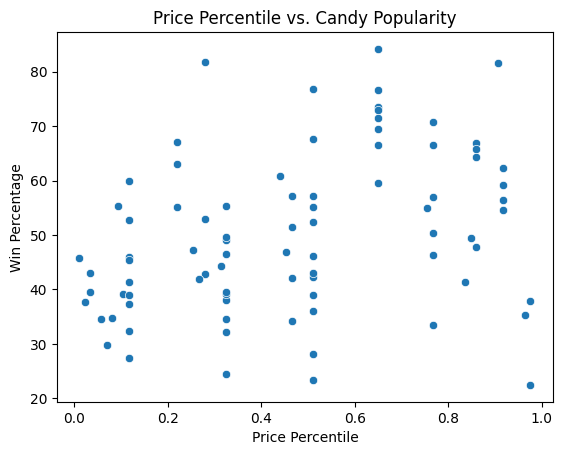

In [41]:
sns.scatterplot(
    data=df,
    x='pricepercent',
    y='winpercent'
)

plt.title('Price Percentile vs. Candy Popularity')
plt.xlabel('Price Percentile')
plt.ylabel('Win Percentage')
plt.show()

Price percentile showed a weak-to-moderate positive correlation with candy popularity (r = 0.345). Although higher-priced candies tended to have higher win percentages, the wide dispersion in the scatter plot indicates that price alone is not a strong predictor of popularity.

Chocolate was the attribute most strongly associated with candy popularity in the dataset. It showed the highest positive correlation with win percentage (r = 0.637). Furthermore, all candies in the top 10 contained chocolate, while none of the bottom 10 did. These findings suggest a strong association between chocolate and consumer preference within the dataset, although they do not establish causation.

## Limitations

This analysis has some limitations that should be considered when interpreting the results:

- **Sample size:** The dataset contains only 85 candy products, which may limit the representativeness of the findings.
- **Generalizability:** The observed preferences may not reflect the preferences of all consumers or populations.
- **Measurement:** Win percentage represents pairwise comparison results rather than actual sales or market share.
- **Correlation:** Associations between candy attributes and popularity do not establish causal relationships.

Therefore, the findings should be interpreted as exploratory observations rather than definitive conclusions about consumer preferences.